In [36]:
import pandas as pd
import numpy as np

In [42]:
# load best_tabular_model_probabilites_train.csv
df = pd.read_csv('best_tabular_fold_probabilities_train.csv')
df_valid = pd.read_csv('best_tabular_fold_probabilities.csv')

df_vit_train = pd.read_csv('vit_train_probabilities.csv')

In [43]:
print(df.head())

         id  prob_class_1  target
0   94956.0      0.945709     1.0
1   98697.0      0.056177     0.0
2  214227.0      0.962947     1.0
3  220143.0      0.035090     0.0
4   58291.0      0.014899     0.0


In [44]:
#check data types
print(df.dtypes)
print(df_valid.dtypes)
#print shapes
print(df.shape)
print(df_valid.shape)

id              float64
prob_class_1    float64
target          float64
dtype: object
id              float64
prob_class_1    float64
target          float64
dtype: object
(4573, 3)
(1751, 3)


In [45]:
print(df_vit_train.dtypes)

id          float64
target_0    float64
target_1    float64
dtype: object


In [46]:
#merga df and df_vit_train by id
df = pd.merge(df, df_vit_train, on="id", how="inner")
df_valid = pd.merge(df_valid, df_vit_train, on="id", how="inner")
y = df["target"]
y_valid = df_valid["target"]


Accuracy: 0.918200408997955
              precision    recall  f1-score   support

         0.0       0.92      0.96      0.94       635
         1.0       0.91      0.85      0.88       343

    accuracy                           0.92       978
   macro avg       0.92      0.90      0.91       978
weighted avg       0.92      0.92      0.92       978

ROC AUC: 0.9627717453685635


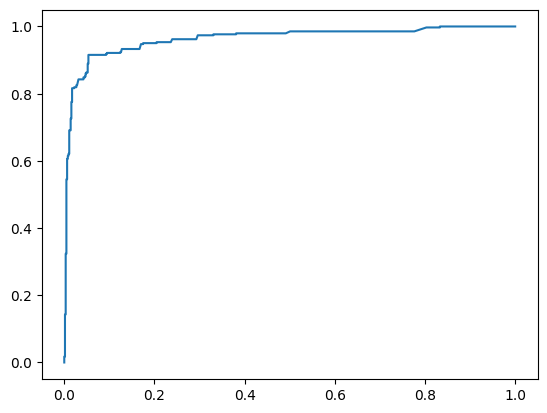

In [49]:
#xgboost model
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report

#split data
X = df.drop(columns=["id", "target"])
X_valid = df_valid.drop(columns=["id", "target"])
#validation set will act as test set
model = XGBClassifier()
model.fit(X, y)
y_pred = model.predict(X_valid)
accuracy = accuracy_score(y_valid, y_pred)
roc_auc = roc_auc_score(y_valid, y_pred)
print(f"Accuracy: {accuracy}")
print(classification_report(y_valid, y_pred))
#print roc 
print(f"ROC AUC: {roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])}")

#print curve
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
fpr, tpr, thresholds = roc_curve(y_valid, model.predict_proba(X_valid)[:, 1])
plt.plot(fpr, tpr)

